# Selección de la cartera de 3 acciones (Reto 9)

Queremos elegir la cartera para la call asiática con estructura *barbell*: 2 acciones no volátiles y 1 volátil, a partir de las 30 empresas del Dow Jones.

Pasos: 1. Datos · 2. Separación en volátiles y no volátiles · 3. Empresas volátiles y no volátiles · 4. Todos los tríos posibles

In [1]:
import yfinance as yf
import warnings
warnings.filterwarnings("ignore")

In [2]:
from matplotlib.colors import LinearSegmentedColormap

COLORES = {
    "azul_principal":  "#001391",
    "azul_claro":      "#4D5FC4",
    "azul_muy_claro":  "#B3BAE8",
    "gris_oscuro":     "#1A1A2E",
    "gris_medio":      "#6E7191",
    "gris_claro":      "#E4E4EC",
    "blanco":          "#FFFFFF",
    "acento":          "#FF4B4B",
}

MAPA_CORR = LinearSegmentedColormap.from_list("corr", [COLORES["acento"], COLORES["blanco"], COLORES["azul_principal"]])

## 1. Datos

Usamos los datos limpios del equipo de limpieza (`Datos/dowjones_limpio.csv`, rama `limpieza`), con una fila por fecha y empresa. Los pasamos a formato ancho (una columna por empresa) con el precio ajustado `adj_close`, que ya corrige splits y dividendos, igual que `auto_adjust=True` en yfinance.

In [3]:
import pandas as pd

limpio = pd.read_csv("Datos/dowjones_limpio.csv")
limpio["date"] = pd.to_datetime(limpio["date"], utc=True).dt.tz_localize(None)   

precios = limpio.pivot(index="date", columns="symbol", values="adj_close")
print(f"Datos de {precios.index.min():%Y-%m-%d} a {precios.index.max():%Y-%m-%d}")
precios

Datos de 2018-06-06 a 2025-12-31


symbol,AAPL,AMGN,AMZN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,...,MSFT,NKE,NVDA,PG,SHW,TRV,UNH,V,VZ,WMT
date,,,,,,,,,,,,,,,,,,,,,
2018-06-06,45.665340,143.140976,84.787498,90.234459,357.617035,131.875412,133.010803,34.746960,86.575134,96.091454,...,94.516281,66.114006,6.548116,59.841743,122.481842,107.609100,215.247894,128.590698,30.231352,24.945869
2018-06-07,45.542931,142.946014,84.464996,90.690247,354.700775,131.689972,130.420258,34.268085,89.087196,96.619476,...,93.031548,66.122833,6.492550,60.976597,122.330109,109.097137,215.533524,126.288345,30.606049,25.060925
2018-06-08,45.128613,143.725845,84.199501,90.261292,355.634369,130.872711,131.028625,34.134617,88.722343,98.043266,...,93.723190,66.246658,6.477237,62.119492,123.249725,110.400223,217.005142,127.137566,30.712214,24.886869
2018-06-11,45.017960,143.967621,84.456001,90.440002,357.020355,131.698410,131.470200,34.299484,89.508209,98.392136,...,93.188316,65.972481,6.436242,62.401222,123.395248,109.710838,219.688766,126.354385,30.787148,24.869171
2018-06-12,45.265144,144.326370,84.937500,90.019981,356.712311,132.701141,133.707504,34.495758,89.171417,98.373283,...,93.428093,65.707153,6.484647,62.167809,124.609024,108.937393,219.515594,127.250824,30.481150,24.810167
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-24,273.066711,327.263550,232.380005,378.844177,218.160004,580.214355,263.453613,76.601845,146.411560,113.609474,...,484.943390,58.455666,188.169678,141.343964,323.045959,290.561615,321.228973,353.020142,37.804249,110.903748
2025-12-26,272.657837,326.254211,232.520004,376.807129,216.440002,579.458984,264.267975,76.739304,145.944580,112.696465,...,484.635345,59.361725,190.085205,141.588501,323.135315,288.860809,325.396545,352.880981,37.954269,111.032936
2025-12-29,273.016876,323.020386,232.070007,371.140900,217.250000,575.095581,264.416992,76.376030,146.888229,113.321678,...,484.029236,59.634518,187.780594,141.422211,322.926819,288.672913,322.562622,352.493317,37.954269,111.817924


## 2. Separación en volátiles y no volátiles

La medida de riesgo que usamos es la **volatilidad anualizada**: la desviación típica de las rentabilidades diarias, escalada a un año.

$$
\sigma_{anual} = \sigma_{diaria} \cdot \sqrt{252}
$$

- Se multiplica por $\sqrt{252}$ porque un año tiene unos 252 días de bolsa y, si las rentabilidades diarias son aproximadamente independientes, la **varianza crece linealmente con el tiempo**.
- Anualizar permite comparar la volatilidad con otras magnitudes del notebook.

**No fijamos el corte de antemano.** Primero calculamos y dibujamos la volatilidad de las 30 empresas, sin grupos, y el punto de corte lo decidimos **a la vista de cómo se reparten**. Así el criterio queda justificado por los datos y no por una cifra arbitraria.

### 2.1 Volatilidad de cada empresa

Para cada empresa calculamos las rentabilidades diarias simples con `pct_change` sobre el precio ajustado (`adj_close`, que ya incorpora dividendos y splits, de modo que un dividendo no se confunde con una caída del precio). Después tomamos la desviación típica de cada columna, la anualizamos y ordenamos de menor a mayor.

Usamos `fill_method=None` para que los huecos de datos **no se rellenen artificialmente** con el precio anterior, ya que eso fabricaría rentabilidades de 0 % que reducirían la volatilidad de forma falsa.

In [4]:
import numpy as np, matplotlib.pyplot as plt

DIAS_ANIO = 252
rent = precios.pct_change(fill_method=None) 
vol = (rent.std() * np.sqrt(DIAS_ANIO)).sort_values()

### 2.2 Gráfico de volatilidades (todavía sin grupos)

El gráfico tiene dos paneles que se leen juntos:

- **Izquierda: distribución de las volatilidades.** Es una curva suavizada y cada marca negra del eje es una empresa. Las líneas discontinuas son los percentiles 25, 50 y 75. Sirve para ver **cómo se agrupan** las empresas: dónde está la masa central y si hay una cola hacia volatilidades altas.
- **Derecha: volatilidad de cada empresa**, con su percentil al lado.

Lo que buscamos es una zona donde las empresas empiecen a separarse claramente del grueso. Esa zona es la candidata a frontera entre ambos grupos.

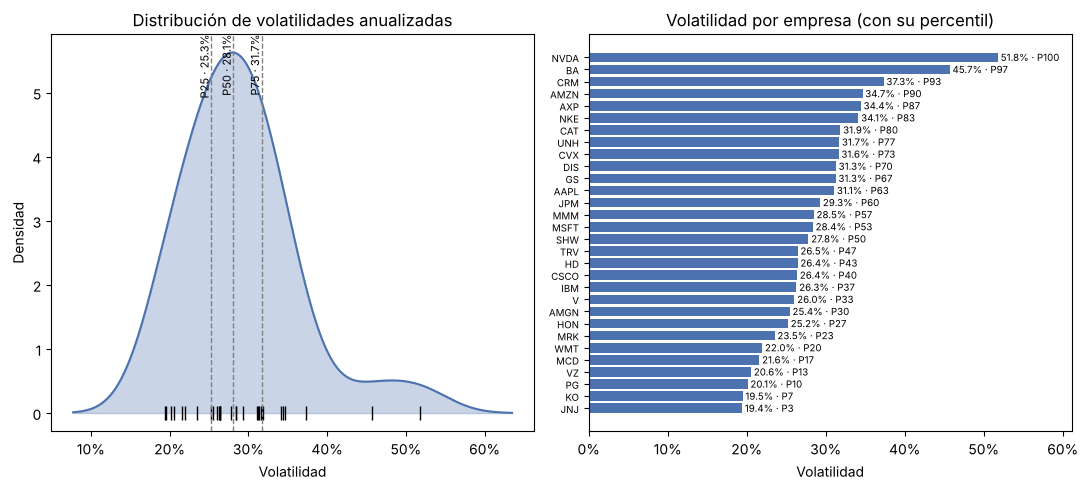

In [5]:
pct = vol.rank(pct=True).round(2)                            
fmt = lambda x, _: f"{x:.0%}"

def grafico(rojas=()):
    """Curva de distribución + barras por empresa. Las empresas de `rojas` salen en rojo."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))

    h = 1.06 * vol.std() * len(vol) ** -0.2                
    x = np.linspace(vol.min() - 3 * h, vol.max() + 3 * h, 300)
    dens = np.exp(-0.5 * ((x[:, None] - vol.values) / h) ** 2).sum(axis=1) / (len(vol) * h * np.sqrt(2 * np.pi))
    ax1.plot(x, dens, color="#4c72b0")
    ax1.fill_between(x, dens, color="#4c72b0", alpha=0.3)
    ax1.plot(vol, np.zeros(len(vol)), "|", color="black", ms=10, clip_on=False) 
    for q in (0.25, 0.50, 0.75):
        v = vol.quantile(q)
        ax1.axvline(v, color="gray", ls="--", lw=1)
        ax1.text(v, ax1.get_ylim()[1], f"P{q*100:.0f} · {v:.1%}", rotation=90, va="top", ha="right", fontsize=8)
    ax1.set(title="Distribución de volatilidades anualizadas", xlabel="Volatilidad", ylabel="Densidad")

    ax2.barh(vol.index, vol, color=["#c44e52" if e in rojas else "#4c72b0" for e in vol.index])
    for i, (v, p) in enumerate(zip(vol, pct)):
        ax2.text(v, i, f" {v:.1%} · P{p*100:.0f}", va="center", fontsize=7)
    ax2.set(title="Volatilidad por empresa (con su percentil)", xlabel="Volatilidad")
    ax2.tick_params(axis="y", labelsize=7)
    ax2.margins(x=0.18)

    if len(rojas):                                           
        corte = vol[list(rojas)].min()
        ax1.fill_between(x, dens, where=x >= corte - 1e-9, color="#c44e52", alpha=0.5)
        for ax in (ax1, ax2):
            ax.axvline(corte, color="#c44e52", lw=1.2)

    for ax in (ax1, ax2):
        ax.xaxis.set_major_formatter(fmt)
    plt.tight_layout()
    plt.show()

grafico()

### 2.3 Corte en P83: grupos volátiles y no volátiles

Con la distribución a la vista, fijamos el corte en el **percentil 83**: una empresa es **volátil** si su percentil de volatilidad es mayor o igual que 0,83.

Con 30 empresas, esto deja:

- **6 empresas volátiles**.
- **24 empresas no volátiles**.

Las líneas y la zona roja del gráfico marcan el corte. El parámetro `CORTE_PCT` se puede cambiar para ver cómo se mueven los grupos, pero conviene recordar que **modifica todo lo que viene después**: el número de empresas volátiles y no volátiles determina cuántos tríos se evalúan en la sección 4.

VOLÁTILES (6): ['NKE', 'AXP', 'AMZN', 'CRM', 'BA', 'NVDA']
NO VOLÁTILES (24): ['JNJ', 'KO', 'PG', 'VZ', 'MCD', 'WMT', 'MRK', 'HON', 'AMGN', 'V', 'IBM', 'CSCO', 'HD', 'TRV', 'SHW', 'MSFT', 'MMM', 'JPM', 'AAPL', 'GS', 'DIS', 'CVX', 'UNH', 'CAT']


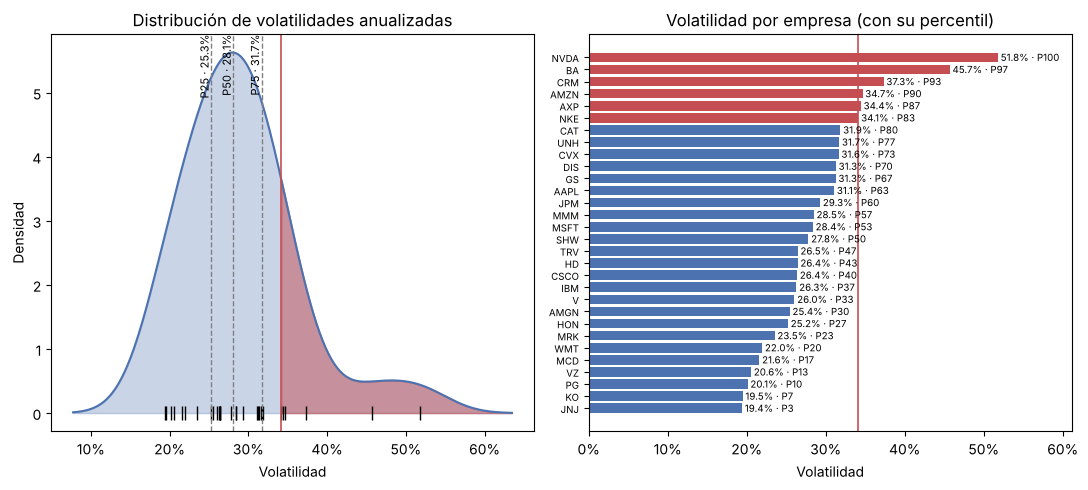

In [6]:
CORTE_PCT = 0.83   

tabla = vol.rename("volatilidad").to_frame().assign(volatil=pct >= CORTE_PCT)
volatiles = tabla.index[tabla["volatil"]].tolist()
no_volatiles = tabla.index[~tabla["volatil"]].tolist()
print(f"VOLÁTILES ({len(volatiles)}): {volatiles}")
print(f"NO VOLÁTILES ({len(no_volatiles)}): {no_volatiles}")

grafico(volatiles)  

**Por qué esta separación encaja con el *barbell*.** Un grupo volátil pequeño y bien separado nos permite escoger **una sola acción de riesgo alto** sin que el resto de la cartera se contagie de esa volatilidad, mientras que un grupo no volátil amplio nos da mucho margen para encontrar **dos acciones estables y poco correlacionadas entre sí**.

## 3. Empresas volátiles y no volátiles

Estas son las empresas de cada grupo con su volatilidad anualizada.

In [7]:
for nombre, grupo in [("VOLÁTILES", volatiles), ("NO VOLÁTILES", no_volatiles)]:
    print(nombre)
    display(vol[grupo].sort_values(ascending=False).round(3).to_frame("volatilidad"))

VOLÁTILES


,volatilidad
symbol,
NVDA,0.518
BA,0.457
CRM,0.373
AMZN,0.347
AXP,0.344
NKE,0.341


NO VOLÁTILES


,volatilidad
symbol,
CAT,0.319
UNH,0.317
CVX,0.316
DIS,0.313
GS,0.313
AAPL,0.311
JPM,0.293
MMM,0.285
MSFT,0.284


## 4. Todos los tríos posibles: 2 no volátiles + 1 volátil

Con los dos grupos definidos, **no escogemos la cartera a ojo**: evaluamos todas las combinaciones posibles y dejamos que los datos decidan. El proceso tiene tres fases:

1. **Generar los candidatos.** Todos los tríos de 2 no volátiles + 1 volátil. Cada trío es una cartera a pesos iguales, por lo que su rentabilidad diaria es la media de las tres.
2. **Filtros duros**:
   - las 3 empresas deben estar en **sectores distintos**;
   - la **correlación media** entre las tres debe ser como máximo **0,40**.
3. **Puntuación** de los tríos que sobreviven: media de 5 percentiles.

Las métricas que se calculan para cada trío (todas anualizadas, con tasa libre de riesgo $r_f = 1\,\%$) son:

| Métrica | Qué mide |
|---|---|
| Rentabilidad | Media de las rentabilidades diarias × 252 |
| Sharpe | Rentabilidad por encima de $r_f$ por unidad de volatilidad total |
| Sortino | Igual que Sharpe, pero penalizando solo la volatilidad **a la baja** |
| Drawdown | Mayor caída desde un máximo hasta un mínimo posterior (el peor momento del inversor) |
| Correlación media | Media de las 3 correlaciones entre pares del trío |

**Por qué usamos percentiles y no los valores directos:** cada métrica tiene una escala distinta. Convertir cada una a percentil entre los tríos candidatos las pone en la misma escala de 0 a 1, y promediar los cinco hace que **ninguna métrica domine** sobre las demás.

### 4.1 Sector de cada empresa

El filtro de sectores evita que la cartera quede concentrada sin darnos cuenta: dos empresas del mismo sector suelen reaccionar igual ante las mismas noticias, y entonces la cartera tiene menos diversificación real de la que aparenta.

Los sectores se consultan una vez en Yahoo Finance (`yf.Ticker(t).info["sector"]`) y se **copian a un diccionario fijo** (`sector`) en la celda siguiente. Así el resultado es reproducible aunque Yahoo cambie su clasificación o no esté disponible.

In [8]:
yahoo = {t: yf.Ticker(t).info.get("sector") for t in sorted(precios.columns)}
filas = [f'"{t}": "{s}"' for t, s in yahoo.items()]
print("{\n" + ",\n".join("    " + ", ".join(filas[i:i + 4]) for i in range(0, len(filas), 4)) + ",\n}")

{
    "AAPL": "Technology", "AMGN": "Healthcare", "AMZN": "Consumer Cyclical", "AXP": "Financial Services",
    "BA": "Industrials", "CAT": "Industrials", "CRM": "Technology", "CSCO": "Technology",
    "CVX": "Energy", "DIS": "Communication Services", "GS": "Financial Services", "HD": "Consumer Cyclical",
    "HON": "Industrials", "IBM": "Technology", "JNJ": "Healthcare", "JPM": "Financial Services",
    "KO": "Consumer Defensive", "MCD": "Consumer Cyclical", "MMM": "Industrials", "MRK": "Healthcare",
    "MSFT": "Technology", "NKE": "Consumer Cyclical", "NVDA": "Technology", "PG": "Consumer Defensive",
    "SHW": "Basic Materials", "TRV": "Financial Services", "UNH": "Healthcare", "V": "Financial Services",
    "VZ": "Communication Services", "WMT": "Consumer Defensive",
}


In [9]:
sector = {
    "AAPL": "Technology", "AMGN": "Healthcare", "AMZN": "Consumer Cyclical", "AXP": "Financial Services",
    "BA": "Industrials", "CAT": "Industrials", "CRM": "Technology", "CSCO": "Technology",
    "CVX": "Energy", "DIS": "Communication Services", "GS": "Financial Services", "HD": "Consumer Cyclical",
    "HON": "Industrials", "IBM": "Technology", "JNJ": "Healthcare", "JPM": "Financial Services",
    "KO": "Consumer Defensive", "MCD": "Consumer Cyclical", "MMM": "Industrials", "MRK": "Healthcare",
    "MSFT": "Technology", "NKE": "Consumer Cyclical", "NVDA": "Technology", "PG": "Consumer Defensive",
    "SHW": "Basic Materials", "TRV": "Financial Services", "UNH": "Healthcare", "V": "Financial Services",
    "VZ": "Communication Services", "WMT": "Consumer Defensive",
}

### 4.2 Correlaciones entre las 30 empresas

La matriz muestra la correlación entre las rentabilidades diarias de todas las parejas de empresas:

- **Azul intenso:** correlación alta y positiva (se mueven juntas).
- **Blanco:** correlación cercana a 0 (se mueven de forma independiente).
- **Rojo:** correlación negativa (tienden a moverse en sentido contrario). Es poco frecuente entre acciones de un mismo índice.

Es habitual ver **bloques azules entre empresas del mismo sector** (por ejemplo, los bancos o las tecnológicas), lo que justifica el filtro de sectores. También permite entender por qué el umbral de correlación media se fija en un valor tan bajo como 0,40: casi todas las parejas del Dow Jones tienen correlación positiva, así que encontrar tríos poco correlacionados es una **condición exigente**.

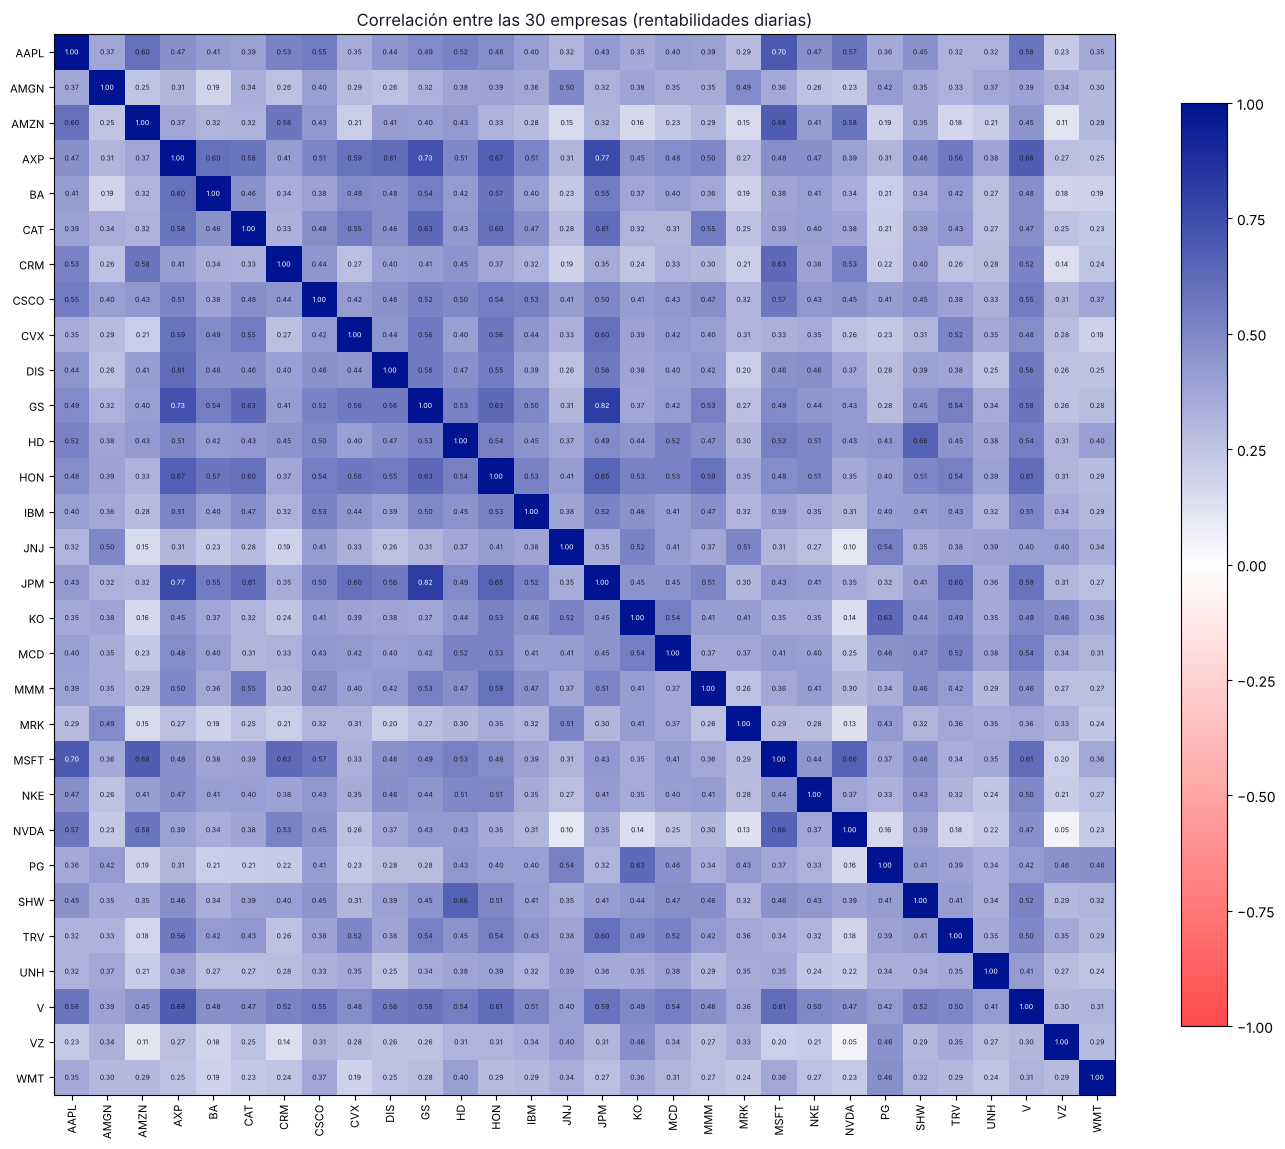

In [10]:
corr30 = rent.corr()
n = len(corr30)

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr30, cmap=MAPA_CORR, vmin=-1, vmax=1)
ax.set_xticks(range(n), corr30.columns, rotation=90, fontsize=8)
ax.set_yticks(range(n), corr30.index, fontsize=8)
for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{corr30.iloc[i, j]:.2f}", ha="center", va="center", fontsize=5,
                color="white" if corr30.iloc[i, j] > 0.7 else COLORES["gris_oscuro"])
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlación entre las 30 empresas (rentabilidades diarias)", color=COLORES["gris_oscuro"])
plt.tight_layout()
plt.show()

### 4.3 Tríos y filtros duros

Cada trío es una cartera a pesos iguales (1/3 cada uno, rebalanceado a diario), así que su rentabilidad diaria es simplemente la media de las tres acciones.

La función `metricas` calcula para cada trío rentabilidad, volatilidad, Sharpe, Sortino y drawdown. El Sortino usa como **desviación a la baja** solo los días en que la rentabilidad queda por debajo de la tasa libre de riesgo diaria ($r_f/252$), de modo que no castiga las subidas.

A continuación se aplican los **filtros duros**: primero se descartan los tríos con sectores repetidos y después los que superan la correlación media máxima de 0,40. Las columnas `corr_media` y `corr_max` quedan guardadas para la puntuación y para los gráficos posteriores. El límite de correlación para las parejas (0,70) se decide más adelante.

In [11]:
from itertools import combinations

rf = 0.01   # tasa libre de riesgo del enunciado (1 %)

def metricas(r):
    """Métricas anualizadas de una serie de rentabilidades diarias."""
    mu, sigma = r.mean() * DIAS_ANIO, r.std() * np.sqrt(DIAS_ANIO)
    caidas = np.minimum(r - rf / DIAS_ANIO, 0)
    acum = (1 + r).cumprod()
    return pd.Series({
        "rentabilidad": mu,
        "volatilidad": sigma,
        "sharpe": (mu - rf) / sigma,
        "sortino": (mu - rf) / np.sqrt((caidas**2).mean() * DIAS_ANIO),
        "drawdown": (acum / acum.cummax() - 1).min(),
    })

In [12]:
# Todos los tríos de 2 no volátiles + 1 volátil, con las 3 empresas en sectores distintos
todos = pd.DataFrame({
    " + ".join([*par, v]): metricas(rent[[*par, v]].mean(axis=1).dropna())
    for par in combinations(no_volatiles, 2)
    for v in volatiles
    if len({sector[e] for e in [*par, v]}) == 3
}).T

corr = [rent[t.split(" + ")].corr().values[np.triu_indices(3, 1)] for t in todos.index]
todos["corr_media"] = [c.mean() for c in corr]
todos["corr_max"] = [c.max() for c in corr]

# Filtro duro: correlación media máxima de 0,40 (el límite para las parejas, 0,70, lo decidimos después)
CORR_MEDIA_MAX = 0.40
print(f"{len(todos)} tríos con 3 sectores distintos")
todos = todos[todos["corr_media"] <= CORR_MEDIA_MAX]
print(f"{len(todos)} tríos con correlación media <= {CORR_MEDIA_MAX}")

1109 tríos con 3 sectores distintos
780 tríos con correlación media <= 0.4


### 4.4 Puntuación de cada trío

Para cada trío que supera los filtros calculamos su **percentil** (entre todos los supervivientes) en cinco criterios: Sharpe, Sortino, drawdown, rentabilidad y baja correlación media. En la correlación el signo va **invertido**, porque cuanto más baja mejor. La **puntuación** es la media de los cinco percentiles, y el trío con la puntuación más alta es el elegido.

La tabla muestra los 10 mejores. Lo que importa mirar es si el primero gana por una sola métrica extrema o por ser **consistentemente bueno en las cinco**; el gráfico siguiente lo aclara.

In [13]:
# Media de 5 percentiles entre los tríos que pasan los filtros (más es mejor; la correlación puntúa al revés)
pct = todos[["sharpe", "sortino", "drawdown", "rentabilidad"]].rank(pct=True)
pct["baja_corr"] = (-todos["corr_media"]).rank(pct=True)
todos["puntuacion"] = pct.mean(axis=1)

todos = todos.sort_values("puntuacion", ascending=False)
todos.head(10).round(3)

,rentabilidad,volatilidad,sharpe,sortino,drawdown,corr_media,corr_max,puntuacion
WMT + MRK + NVDA,0.312,0.231,1.307,1.969,-0.261,0.197,0.237,0.979
JNJ + WMT + NVDA,0.305,0.225,1.313,1.979,-0.291,0.221,0.338,0.953
PG + MRK + NVDA,0.282,0.228,1.192,1.785,-0.270,0.238,0.428,0.943
WMT + AMGN + NVDA,0.313,0.242,1.252,1.887,-0.286,0.250,0.295,0.942
WMT + TRV + NVDA,0.321,0.241,1.295,1.902,-0.303,0.232,0.292,0.940
WMT + UNH + NVDA,0.301,0.253,1.152,1.699,-0.286,0.231,0.245,0.932
JNJ + TRV + NVDA,0.286,0.232,1.191,1.739,-0.297,0.220,0.382,0.931
KO + MRK + NVDA,0.276,0.226,1.176,1.742,-0.289,0.226,0.407,0.929
MRK + TRV + NVDA,0.293,0.240,1.177,1.707,-0.297,0.224,0.364,0.928
WMT + CVX + NVDA,0.307,0.254,1.168,1.715,-0.302,0.228,0.264,0.924


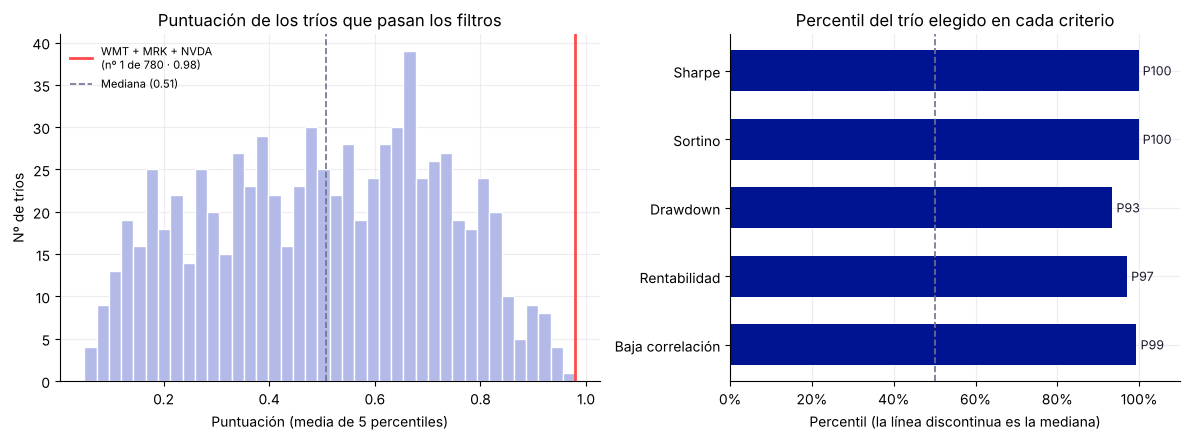

In [14]:
elegida = todos.index[0]   # trío nº 1 por puntuación

# Percentil del trío en cada criterio, calculado entre los tríos que pasan los filtros
metr = todos[["sharpe", "sortino", "drawdown", "rentabilidad"]].rank(pct=True)
metr["baja_corr"] = (-todos["corr_media"]).rank(pct=True)
nombres = {"sharpe": "Sharpe", "sortino": "Sortino", "drawdown": "Drawdown",
           "rentabilidad": "Rentabilidad", "baja_corr": "Baja correlación"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.2, 1]})

# Izquierda: distribución de la puntuación de todos los tríos
ax1.hist(todos["puntuacion"], bins=40, color=COLORES["azul_muy_claro"], edgecolor=COLORES["blanco"])
ax1.axvline(todos.loc[elegida, "puntuacion"], color=COLORES["acento"], lw=2,
            label=f"{elegida}\n(nº 1 de {len(todos)} · {todos.loc[elegida, 'puntuacion']:.2f})")
ax1.axvline(todos["puntuacion"].median(), color=COLORES["gris_medio"], ls="--", lw=1.2,
            label=f"Mediana ({todos['puntuacion'].median():.2f})")
ax1.set(title="Puntuación de los tríos que pasan los filtros", xlabel="Puntuación (media de 5 percentiles)", ylabel="Nº de tríos")
ax1.legend(frameon=False, fontsize=8)

# Derecha: percentil de nuestro trío en cada criterio
vals = metr.loc[elegida].rename(nombres)[::-1]
ax2.barh(vals.index, vals.values, color=COLORES["azul_principal"], height=0.6)
ax2.axvline(0.5, color=COLORES["gris_medio"], ls="--", lw=1.2)
for i, v in enumerate(vals.values):
    ax2.text(v + 0.01, i, f"P{v*100:.0f}", va="center", fontsize=9, color=COLORES["gris_oscuro"])
ax2.set_xlim(0, 1.1)
ax2.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax2.set(title="Percentil del trío elegido en cada criterio", xlabel="Percentil (la línea discontinua es la mediana)")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(color=COLORES["gris_claro"], alpha=0.7)
plt.tight_layout()
plt.show()

### 4.5 Sharpe frente a correlación media

Cada punto es un trío que ha pasado los filtros. En el eje horizontal está su correlación media y en el vertical su Sharpe. Los **10 mejores por puntuación** salen en azul oscuro y el **primero en rojo**.

Si la diversificación funciona, esperamos que los mejores tríos se concentren en la parte **alta** (buen Sharpe) y hacia la **izquierda** (poca correlación). Esto confirma visualmente que premiar la baja correlación en la puntuación no es un capricho: los tríos más diversificados tienden a ser también los más eficientes.

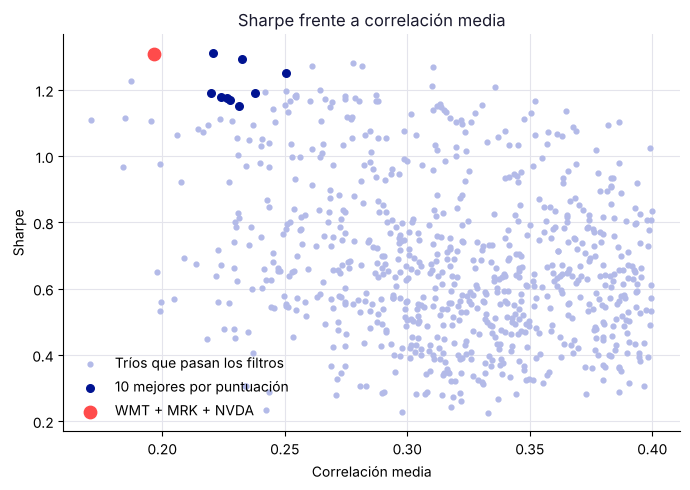

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(todos["corr_media"], todos["sharpe"], s=12, color=COLORES["azul_muy_claro"], label="Tríos que pasan los filtros")
ax.scatter(todos["corr_media"][:10], todos["sharpe"][:10], s=30, color=COLORES["azul_principal"], label="10 mejores por puntuación")
ax.scatter(todos["corr_media"].iloc[0], todos["sharpe"].iloc[0], s=80, color=COLORES["acento"], label=todos.index[0])
ax.set(xlabel="Correlación media", ylabel="Sharpe")
ax.set_title("Sharpe frente a correlación media", color=COLORES["gris_oscuro"])
ax.grid(color=COLORES["gris_claro"])
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 4.6 Rentabilidad frente a volatilidad: nuestra cartera frente al resto

Este gráfico compara nuestra cartera con **todos los tríos candidatos** en el plano riesgo–rentabilidad (horizontal: volatilidad; vertical: rentabilidad anual). El mejor trío está en rojo y las tres acciones que lo forman, por separado, en negro.

Hay dos lecturas:

- **Frente al resto de tríos:** una cartera es mejor cuanto más arriba (más rentabilidad) y más a la izquierda (menos riesgo) esté. Lo ideal es que nuestro punto quede hacia el borde superior-izquierdo de la nube.
- **Frente a sus propias componentes:** la cartera combina acciones muy distintas, por lo que su volatilidad suele quedar **por debajo de la media de las volatilidades individuales**. Esa diferencia es el beneficio de la diversificación.

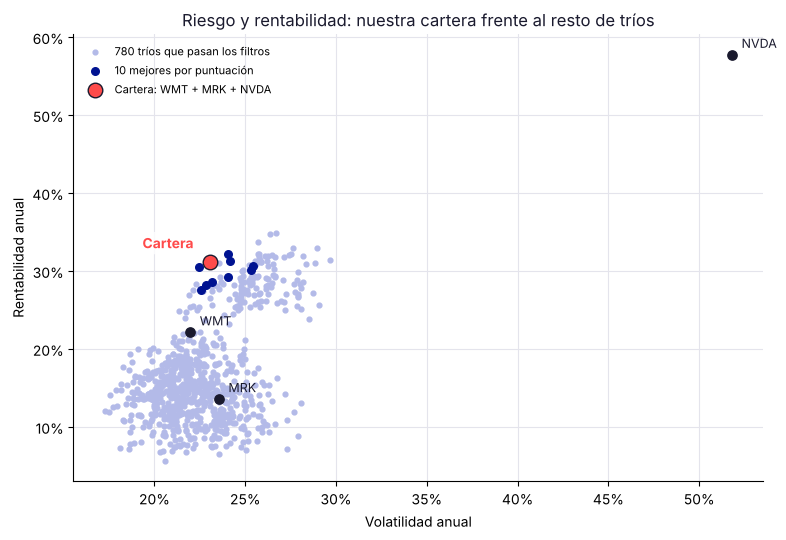

Volatilidad media de las 3 acciones por separado: 32.4%
Volatilidad de la cartera (a pesos iguales):      23.1%
Reducción por diversificación:                    9.4% puntos


In [16]:
elegida = todos.index[0]
componentes = elegida.split(" + ")
x_c, y_c = todos.loc[elegida, "volatilidad"], todos.loc[elegida, "rentabilidad"]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(todos["volatilidad"], todos["rentabilidad"], s=12, color=COLORES["azul_muy_claro"],
           label=f"{len(todos)} tríos que pasan los filtros")
ax.scatter(todos["volatilidad"][:10], todos["rentabilidad"][:10], s=30, color=COLORES["azul_principal"],
           label="10 mejores por puntuación")

# Las tres acciones por separado
vols_ind = []
for e in componentes:
    v_e, r_e = rent[e].std() * np.sqrt(DIAS_ANIO), rent[e].mean() * DIAS_ANIO
    vols_ind.append(v_e)
    ax.scatter(v_e, r_e, s=45, color=COLORES["gris_oscuro"], zorder=3)
    ax.annotate(e, (v_e, r_e), textcoords="offset points", xytext=(7, 5), fontsize=9, color=COLORES["gris_oscuro"])

# Nuestra cartera
ax.scatter(x_c, y_c, s=110, color=COLORES["acento"], edgecolor=COLORES["gris_oscuro"], zorder=4, label=f"Cartera: {elegida}")
ax.annotate("Cartera", (x_c, y_c), textcoords="offset points", xytext=(-12, 10), ha="right", fontsize=10,
            fontweight="bold", color=COLORES["acento"],
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))

ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set(xlabel="Volatilidad anual", ylabel="Rentabilidad anual")
ax.set_title("Riesgo y rentabilidad: nuestra cartera frente al resto de tríos", color=COLORES["gris_oscuro"])
ax.grid(color=COLORES["gris_claro"])
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

print(f"Volatilidad media de las 3 acciones por separado: {np.mean(vols_ind):.1%}")
print(f"Volatilidad de la cartera (a pesos iguales):      {x_c:.1%}")
print(f"Reducción por diversificación:                    {np.mean(vols_ind) - x_c:.1%} puntos")

### 4.7 Correlaciones del mejor trío (nº 1 por puntuación)

Para terminar la sección, la matriz de correlaciones del trío elegido. Las correlaciones entre las tres acciones deberían ser **bajas**, de acuerdo con el filtro de 0,40 de media, y es lo que hace que la volatilidad de la cartera sea menor que la de sus partes. Estas correlaciones son las que se usarán en el Montecarlo.

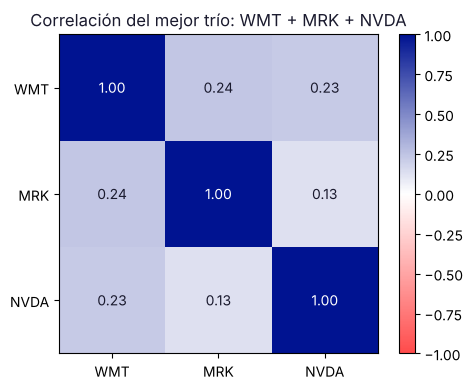

In [17]:
mejor = todos.index[0].split(" + ")
corr = rent[mejor].corr()

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, cmap=MAPA_CORR, vmin=-1, vmax=1)
ax.set_xticks(range(3), mejor)
ax.set_yticks(range(3), mejor)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if corr.iloc[i, j] > 0.7 else COLORES["gris_oscuro"])
fig.colorbar(im)
ax.set_title(f"Correlación del mejor trío: {' + '.join(mejor)}", color=COLORES["gris_oscuro"])
plt.tight_layout()
plt.show()

## 5. Comprobación: ¿nos renta la cartera? Beta y alfa

Hasta ahora hemos demostrado que el trío es **el mejor de los candidatos**. Falta comprobar que además **gana más de lo que le corresponde por el riesgo de mercado que asume**. Para ello usamos el modelo CAPM, con una regresión sobre las rentabilidades **en exceso** de la tasa libre de riesgo:

$$
r_{cartera} - r_f = \alpha + \beta\,(r_{mercado} - r_f) + \varepsilon
$$

- **Beta ($\beta$)**: sensibilidad de la cartera al mercado. $\beta < 1$ implica que se mueve menos que el mercado; $\beta > 1$, más.
- **Alfa ($\alpha$)**: rentabilidad anual **que no se explica por el mercado**. Un alfa positivo significa que la cartera rinde más de lo que le tocaría por su beta.
- **$R^2$**: qué parte de los movimientos de la cartera se explica por el mercado. Si es bajo, la cartera tiene riesgo propio, resultado de la diversificación entre sectores.

Como **mercado** usamos el Dow Jones equiponderado, es decir, la media diaria de las 30 empresas, de modo que no necesitamos descargar ningún dato adicional.

,beta,alfa_anual,t_alfa,R2
Cartera,0.934,0.156,2.858,0.576
WMT,0.546,0.127,1.787,0.218
MRK,0.599,0.033,0.434,0.228
NVDA,1.656,0.310,2.052,0.359


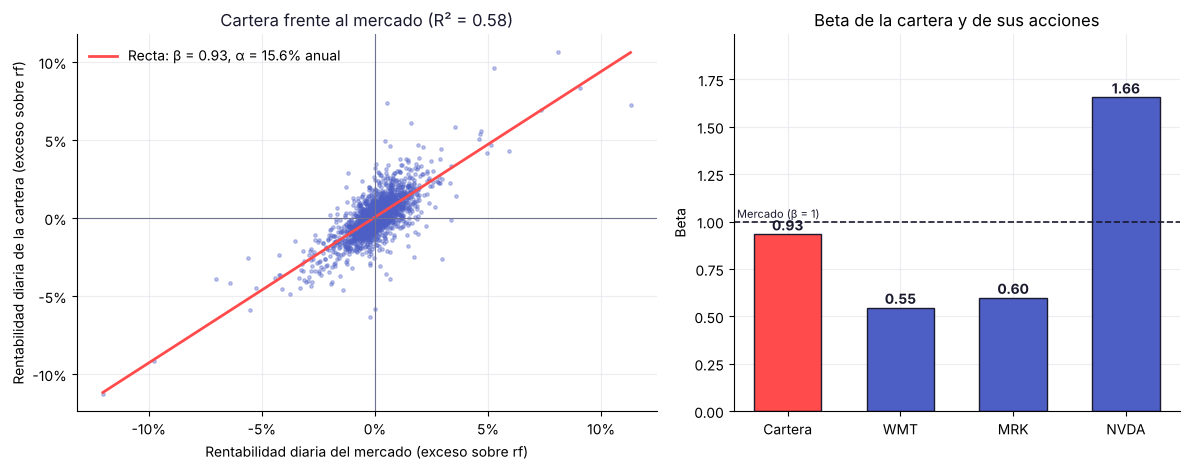

Beta de la cartera = 0.93: se mueve menos que el mercado.
Alfa = 15.6% anual (t = 2.86): significativo al ~95 %.


In [18]:
trio = elegida.split(" + ")

datos = pd.concat([rent.mean(axis=1).rename("Mercado"),
                   rent[trio].mean(axis=1).rename("Cartera"),
                   rent[trio]], axis=1).dropna()
exceso = datos - rf / DIAS_ANIO          # rentabilidades en exceso de la tasa libre de riesgo

def capm(y, x):
    '''Regresión y = alfa + beta·x por mínimos cuadrados, con el t-estadístico del alfa.'''
    n = len(x)
    beta = np.cov(y, x, ddof=1)[0, 1] / np.var(x, ddof=1)
    alfa = y.mean() - beta * x.mean()
    res = y - (alfa + beta * x)
    sxx = ((x - x.mean()) ** 2).sum()
    se_alfa = np.sqrt((res ** 2).sum() / (n - 2) * (1 / n + x.mean() ** 2 / sxx))
    return pd.Series({"beta": beta, "alfa_anual": alfa * DIAS_ANIO, "t_alfa": alfa / se_alfa,
                      "R2": 1 - (res ** 2).sum() / ((y - y.mean()) ** 2).sum()})

tabla_capm = pd.DataFrame({c: capm(exceso[c], exceso["Mercado"]) for c in ["Cartera", *trio]}).T
display(tabla_capm.round(3))

b, a, t, r2 = tabla_capm.loc["Cartera", ["beta", "alfa_anual", "t_alfa", "R2"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})

# Izquierda: regresión de la cartera sobre el mercado
x, y = exceso["Mercado"], exceso["Cartera"]
ax1.scatter(x, y, s=6, alpha=0.35, color=COLORES["azul_claro"])
xs = np.array([x.min(), x.max()])
alfa_d = y.mean() - b * x.mean()
ax1.plot(xs, alfa_d + b * xs, color=COLORES["acento"], lw=2, label=f"Recta: β = {b:.2f}, α = {a:.1%} anual")
ax1.axhline(0, color=COLORES["gris_medio"], lw=0.8)
ax1.axvline(0, color=COLORES["gris_medio"], lw=0.8)
ax1.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.set(xlabel="Rentabilidad diaria del mercado (exceso sobre rf)", ylabel="Rentabilidad diaria de la cartera (exceso sobre rf)")
ax1.set_title(f"Cartera frente al mercado (R² = {r2:.2f})", color=COLORES["gris_oscuro"])
ax1.legend(frameon=False)

# Derecha: beta de cada acción y de la cartera
betas = tabla_capm["beta"]
colores_b = [COLORES["acento"]] + [COLORES["azul_claro"]] * len(trio)
ax2.bar(betas.index, betas.values, color=colores_b, edgecolor=COLORES["gris_oscuro"], width=0.6)
ax2.axhline(1, color=COLORES["gris_oscuro"], ls="--", lw=1.2)
ax2.text(-0.45, 1.02, "Mercado (β = 1)", ha="left", fontsize=8, color=COLORES["gris_oscuro"])
for i, v in enumerate(betas.values):
    ax2.text(i, v + 0.02, f"{v:.2f}", ha="center", fontweight="bold", color=COLORES["gris_oscuro"])
ax2.set_ylim(0, max(betas.max(), 1) * 1.2)
ax2.set(ylabel="Beta", title="Beta de la cartera y de sus acciones")

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=COLORES["gris_claro"], alpha=0.7)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print(f"Beta de la cartera = {b:.2f}: se mueve {'menos' if b < 1 else 'más'} que el mercado.")
print(f"Alfa = {a:.1%} anual (t = {t:.2f}): {'significativo' if abs(t) > 2 else 'no significativo'} al ~95 %.")

**Cómo interpretar el resultado.**

- **Beta de la cartera.** Si queda por debajo de 1, la cartera amortigua al mercado, que es justo lo que buscaba el *barbell*. En el gráfico de barras se ve la mezcla: lo esperable es que las acciones no volátiles aporten betas bajas y la volátil una beta más alta, quedando la cartera en un punto intermedio.
- **Alfa y su t-estadístico.** Un alfa positivo indica que la cartera ha rendido **por encima de lo que explica el mercado**, y es el argumento de que nos renta. Como regla práctica, un $|t| > 2$ indica que el alfa es estadísticamente distinto de cero; si es menor, el alfa positivo puede ser ruido.
- **$R^2$.** Un valor moderado significa que una parte importante del riesgo de la cartera es **propio** y no de mercado, lo que se debe a la diversificación entre sectores.
- El mercado de referencia (las 30 empresas) **incluye a las tres acciones de la cartera**, lo que acerca ligeramente la beta a 1 y reduce el alfa; es una aproximación razonable, aunque no un índice externo.

## Parámetros para el Montecarlo: volatilidad anual y correlación

Para simular la cartera **WMT + MRK + NVDA** necesitamos conocer cuánto se mueve cada acción ($\sigma$) y cómo se mueven entre ellas ($\rho$).

Usamos las **log-rentabilidades diarias** de los precios ajustados (`adj_close`), desde junio de 2018 hasta diciembre de 2025.

La **volatilidad diaria** se anualiza multiplicando por $\sqrt{252}$, ya que un año tiene aproximadamente 252 días de bolsa:

$$
\sigma_{anual} = \sigma_{diaria} \cdot \sqrt{252}
$$

La **correlación** se calcula directamente sobre las mismas log-rentabilidades diarias.

Los valores obtenidos se copian manualmente en `montecarlo.ipynb` para utilizarlos en la simulación.

In [19]:
cartera = ["WMT", "MRK", "NVDA"]

log_rent = np.log(precios[cartera]).diff().dropna()   # log-rentabilidades diarias de las 3 acciones
sigma = log_rent.std() * np.sqrt(DIAS_ANIO)           # volatilidad anual
rho = log_rent.corr()                                 # matriz de correlaciones

print("sigma =", sigma.tolist())
print("rho =", rho.values.tolist())
rho.round(3)

sigma = [0.21915213991738983, 0.23593284714054694, 0.5174177090715789]
rho = [[1.0, 0.23448210934482588, 0.2254529788801119], [0.23448210934482588, 1.0, 0.12948746520485915], [0.2254529788801119, 0.12948746520485915, 1.0]]


symbol,WMT,MRK,NVDA
symbol,,,
WMT,1.000,0.234,0.225
MRK,0.234,1.000,0.129
NVDA,0.225,0.129,1.000


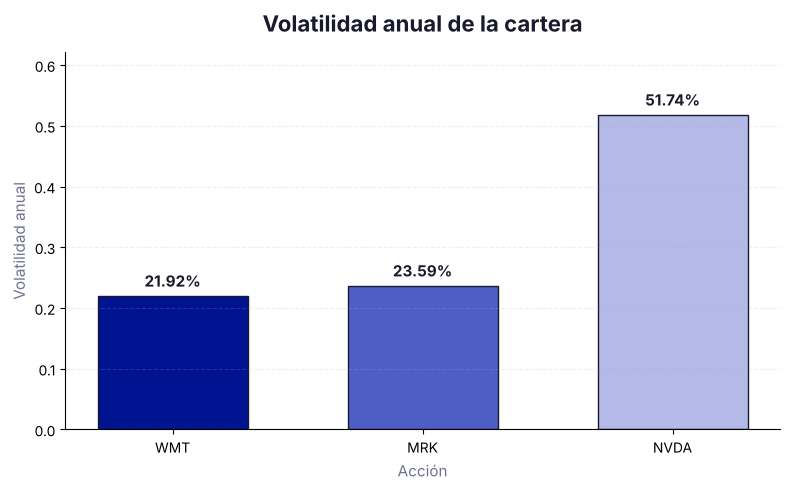

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

colores = [
    COLORES["azul_principal"],
    COLORES["azul_claro"],
    COLORES["azul_muy_claro"]
]

barras = ax.bar(
    sigma.index,
    sigma.values,
    color=colores,
    width=0.6,
    edgecolor=COLORES["gris_oscuro"],
    linewidth=1
)

for barra, valor in zip(barras, sigma.values):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.01,
        f"{valor:.2%}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=COLORES["gris_oscuro"]
    )

ax.set_title(
    "Volatilidad anual de la cartera",
    fontsize=16,
    fontweight="bold",
    color=COLORES["gris_oscuro"],
    pad=15
)

ax.set_ylabel(
    "Volatilidad anual",
    fontsize=11,
    color=COLORES["gris_medio"]
)

ax.set_xlabel(
    "Acción",
    fontsize=11,
    color=COLORES["gris_medio"]
)

ax.set_ylim(0, max(sigma.values) * 1.2)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.2
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()